## 🧑‍⚕️️ Health Insurance Customer Response Prediction

Given *data about a health insurance marketing campaign*, let's try to predict whether a given customer will **purchase** the insurance or not.

We will use a logistic regression model to make our predictions.

Data source: https://www.kaggle.com/datasets/klmsathishkumar/health-insurance-lead-prediction

### Importing Libraries

In [1]:
import numpy as np
import pandas as pd
pd.set_option('display.max_columns', None)

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import confusion_matrix, classification_report

import warnings
warnings.filterwarnings(action='ignore')

In [2]:
data = pd.read_csv('archive/train.csv')
data

,ID,City_Code,Region_Code,Accomodation_Type,Reco_Insurance_Type,Upper_Age,Lower_Age,Is_Spouse,Health Indicator,Holding_Policy_Duration,Holding_Policy_Type,Reco_Policy_Cat,Reco_Policy_Premium,Response
0,1,C3,3213,Rented,Individual,36,36,No,X1,14+,3.0,22,11628.0,0
1,2,C5,1117,Owned,Joint,75,22,No,X2,NaN,NaN,22,30510.0,0
2,3,C5,3732,Owned,Individual,32,32,No,NaN,1.0,1.0,19,7450.0,1
3,4,C24,4378,Owned,Joint,52,48,No,X1,14+,3.0,19,17780.0,0
4,5,C8,2190,Rented,Individual,44,44,No,X2,3.0,1.0,16,10404.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50877,50878,C4,845,Rented,Individual,22,22,No,X3,NaN,NaN,18,7704.0,0
50878,50879,C5,4188,Rented,Individual,27,27,No,X3,7.0,3.0,4,5408.0,0
50879,50880,C1,442,Rented,Individual,63,63,No,X2,14+,1.0,12,11374.0,0
50880,50881,C1,4,Owned,Joint,71,49,No,X2,2.0,2.0,16,28179.2,1


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50882 entries, 0 to 50881
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       50882 non-null  int64  
 1   City_Code                50882 non-null  object 
 2   Region_Code              50882 non-null  int64  
 3   Accomodation_Type        50882 non-null  object 
 4   Reco_Insurance_Type      50882 non-null  object 
 5   Upper_Age                50882 non-null  int64  
 6   Lower_Age                50882 non-null  int64  
 7   Is_Spouse                50882 non-null  object 
 8   Health Indicator         39191 non-null  object 
 9   Holding_Policy_Duration  30631 non-null  object 
 10  Holding_Policy_Type      30631 non-null  float64
 11  Reco_Policy_Cat          50882 non-null  int64  
 12  Reco_Policy_Premium      50882 non-null  float64
 13  Response                 50882 non-null  int64  
dtypes: float64(2), int64(6

### Preprocessing

In [4]:
df = data.copy()

In [5]:
# Drop ID
df = df.drop('ID', axis=1)

In [7]:
df.isna().mean()

City_Code                  0.000000
Region_Code                0.000000
Accomodation_Type          0.000000
Reco_Insurance_Type        0.000000
Upper_Age                  0.000000
Lower_Age                  0.000000
Is_Spouse                  0.000000
Health Indicator           0.229767
Holding_Policy_Duration    0.397999
Holding_Policy_Type        0.397999
Reco_Policy_Cat            0.000000
Reco_Policy_Premium        0.000000
Response                   0.000000
dtype: float64

In [8]:
# Drop columns with too many missing values (more than 25%)
df = df.drop(['Holding_Policy_Duration', 'Holding_Policy_Type'], axis=1)

In [9]:
df.isna().sum()

City_Code                  0
Region_Code                0
Accomodation_Type          0
Reco_Insurance_Type        0
Upper_Age                  0
Lower_Age                  0
Is_Spouse                  0
Health Indicator       11691
Reco_Policy_Cat            0
Reco_Policy_Premium        0
Response                   0
dtype: int64

In [10]:
df

,City_Code,Region_Code,Accomodation_Type,Reco_Insurance_Type,Upper_Age,Lower_Age,Is_Spouse,Health Indicator,Reco_Policy_Cat,Reco_Policy_Premium,Response
0,C3,3213,Rented,Individual,36,36,No,X1,22,11628.0,0
1,C5,1117,Owned,Joint,75,22,No,X2,22,30510.0,0
2,C5,3732,Owned,Individual,32,32,No,NaN,19,7450.0,1
3,C24,4378,Owned,Joint,52,48,No,X1,19,17780.0,0
4,C8,2190,Rented,Individual,44,44,No,X2,16,10404.0,0
...,...,...,...,...,...,...,...,...,...,...,...
50877,C4,845,Rented,Individual,22,22,No,X3,18,7704.0,0
50878,C5,4188,Rented,Individual,27,27,No,X3,4,5408.0,0
50879,C1,442,Rented,Individual,63,63,No,X2,12,11374.0,0
50880,C1,4,Owned,Joint,71,49,No,X2,16,28179.2,1


In [13]:
# Fill missing values
df['Health Indicator'] = df['Health Indicator'].fillna(df['Health Indicator'].mode()[0])

In [15]:
df.dtypes

City_Code               object
Region_Code              int64
Accomodation_Type       object
Reco_Insurance_Type     object
Upper_Age                int64
Lower_Age                int64
Is_Spouse               object
Health Indicator        object
Reco_Policy_Cat          int64
Reco_Policy_Premium    float64
Response                 int64
dtype: object

In [14]:
{column: list(df[column].unique()) for column in df.select_dtypes('object').columns}

{'City_Code': ['C3',
  'C5',
  'C24',
  'C8',
  'C9',
  'C1',
  'C15',
  'C28',
  'C27',
  'C7',
  'C20',
  'C25',
  'C4',
  'C2',
  'C34',
  'C10',
  'C17',
  'C18',
  'C16',
  'C29',
  'C33',
  'C26',
  'C19',
  'C6',
  'C12',
  'C13',
  'C11',
  'C14',
  'C22',
  'C23',
  'C21',
  'C36',
  'C32',
  'C30',
  'C35',
  'C31'],
 'Accomodation_Type': ['Rented', 'Owned'],
 'Reco_Insurance_Type': ['Individual', 'Joint'],
 'Is_Spouse': ['No', 'Yes'],
 'Health Indicator': ['X1', 'X2', 'X4', 'X3', 'X6', 'X5', 'X8', 'X7', 'X9']}

In [18]:
# Drop high-cardinality columns
df = df.drop('Region_Code', axis=1)

In [19]:
# Binary encoding
df['Accomodation_Type'] = df['Accomodation_Type'].replace({'Rented': 0, 'Owned': 1})
df['Reco_Insurance_Type'] = df['Reco_Insurance_Type'].replace({'Individual': 0, 'Joint': 1})
df['Is_Spouse'] = df['Is_Spouse'].replace({'No': 0, 'Yes': 1})

In [20]:
{column: list(df[column].unique()) for column in df.select_dtypes('object').columns}

{'City_Code': ['C3',
  'C5',
  'C24',
  'C8',
  'C9',
  'C1',
  'C15',
  'C28',
  'C27',
  'C7',
  'C20',
  'C25',
  'C4',
  'C2',
  'C34',
  'C10',
  'C17',
  'C18',
  'C16',
  'C29',
  'C33',
  'C26',
  'C19',
  'C6',
  'C12',
  'C13',
  'C11',
  'C14',
  'C22',
  'C23',
  'C21',
  'C36',
  'C32',
  'C30',
  'C35',
  'C31'],
 'Health Indicator': ['X1', 'X2', 'X4', 'X3', 'X6', 'X5', 'X8', 'X7', 'X9']}

In [21]:
# One-hot encoding
for column in ['City_Code', 'Health Indicator', 'Reco_Policy_Cat']:
    dummies = pd.get_dummies(df[column], prefix=column)
    df = pd.concat([df, dummies], axis=1)
    df = df.drop(column, axis=1)

In [22]:
df

,Accomodation_Type,Reco_Insurance_Type,Upper_Age,Lower_Age,Is_Spouse,Reco_Policy_Premium,Response,City_Code_C1,City_Code_C10,City_Code_C11,City_Code_C12,City_Code_C13,City_Code_C14,City_Code_C15,City_Code_C16,City_Code_C17,City_Code_C18,City_Code_C19,City_Code_C2,City_Code_C20,City_Code_C21,City_Code_C22,City_Code_C23,City_Code_C24,City_Code_C25,City_Code_C26,City_Code_C27,City_Code_C28,City_Code_C29,City_Code_C3,City_Code_C30,City_Code_C31,City_Code_C32,City_Code_C33,City_Code_C34,City_Code_C35,City_Code_C36,City_Code_C4,City_Code_C5,City_Code_C6,City_Code_C7,City_Code_C8,City_Code_C9,Health Indicator_X1,Health Indicator_X2,Health Indicator_X3,Health Indicator_X4,Health Indicator_X5,Health Indicator_X6,Health Indicator_X7,Health Indicator_X8,Health Indicator_X9,Reco_Policy_Cat_1,Reco_Policy_Cat_2,Reco_Policy_Cat_3,Reco_Policy_Cat_4,Reco_Policy_Cat_5,Reco_Policy_Cat_6,Reco_Policy_Cat_7,Reco_Policy_Cat_8,Reco_Policy_Cat_9,Reco_Policy_Cat_10,Reco_Policy_Cat_11,Reco_Policy_Cat_12,Reco_Policy_Cat_13,Reco_Policy_Cat_14,Reco_Policy_Cat_15,Reco_Policy_Cat_16,Reco_Policy_Cat_17,Reco_Policy_Cat_18,Reco_Policy_Cat_19,Reco_Policy_Cat_20,Reco_Policy_Cat_21,Reco_Policy_Cat_22
0,0,0,36,36,0,11628.0,0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
1,1,1,75,22,0,30510.0,0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
2,1,0,32,32,0,7450.0,1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
3,1,1,52,48,0,17780.0,0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
4,0,0,44,44,0,10404.0,0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50877,0,0,22,22,0,7704.0,0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,Fa

In [23]:
# Split df into X and y
y = df['Response'].copy()
X = df.drop('Response', axis=1).copy()

In [24]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=True, random_state=1)

In [25]:
y_train.value_counts()

Response
0    27121
1     8496
Name: count, dtype: int64

In [26]:
# Scale X
scaler = StandardScaler()
scaler.fit(X_train)

X_train = pd.DataFrame(scaler.transform(X_train), index=X_train.index, columns=X_train.columns)
X_test = pd.DataFrame(scaler.transform(X_test), index=X_test.index, columns=X_test.columns)

In [27]:
X_train

,Accomodation_Type,Reco_Insurance_Type,Upper_Age,Lower_Age,Is_Spouse,Reco_Policy_Premium,City_Code_C1,City_Code_C10,City_Code_C11,City_Code_C12,City_Code_C13,City_Code_C14,City_Code_C15,City_Code_C16,City_Code_C17,City_Code_C18,City_Code_C19,City_Code_C2,City_Code_C20,City_Code_C21,City_Code_C22,City_Code_C23,City_Code_C24,City_Code_C25,City_Code_C26,City_Code_C27,City_Code_C28,City_Code_C29,City_Code_C3,City_Code_C30,City_Code_C31,City_Code_C32,City_Code_C33,City_Code_C34,City_Code_C35,City_Code_C36,City_Code_C4,City_Code_C5,City_Code_C6,City_Code_C7,City_Code_C8,City_Code_C9,Health Indicator_X1,Health Indicator_X2,Health Indicator_X3,Health Indicator_X4,Health Indicator_X5,Health Indicator_X6,Health Indicator_X7,Health Indicator_X8,Health Indicator_X9,Reco_Policy_Cat_1,Reco_Policy_Cat_2,Reco_Policy_Cat_3,Reco_Policy_Cat_4,Reco_Policy_Cat_5,Reco_Policy_Cat_6,Reco_Policy_Cat_7,Reco_Policy_Cat_8,Reco_Policy_Cat_9,Reco_Policy_Cat_10,Reco_Policy_Cat_11,Reco_Policy_Cat_12,Reco_Policy_Cat_13,Reco_Policy_Cat_14,Reco_Policy_Cat_15,Reco_Policy_Cat_16,Reco_Policy_Cat_17,Reco_Policy_Cat_18,Reco_Policy_Cat_19,Reco_Policy_Cat_20,Reco_Policy_Cat_21,Reco_Policy_Cat_22
47215,-1.102015,-0.509835,-0.684813,-0.561071,-0.449329,-0.260512,-0.459940,-0.180185,-0.151873,-0.130232,-0.142412,-0.121007,-0.155131,-0.15022,-0.150903,-0.125005,-0.135592,-0.425273,-0.137512,-0.120048,-0.101755,-0.109369,-0.103154,-0.084076,-0.100051,-0.073812,-0.074957,-0.089335,3.059379,-0.032681,-0.018358,-0.054635,-0.075335,-0.050051,-0.029988,-0.02542,-0.278694,-0.167499,-0.201145,-0.197337,-0.192839,-0.210919,-0.972826,1.98114,-0.391043,-0.355989,-0.188570,-0.158979,-0.061453,-0.039327,-0.03635,-0.19818,-0.196182,-0.146364,-0.143944,-0.141486,-0.128775,-0.129225,-0.126503,-0.128549,-0.122786,-0.12255,-0.210337,-0.185919,-0.18519,-0.183644,-0.293850,-0.283115,-0.349042,-0.280037,3.877689,-0.33501,-0.386594
18464,0.907429,-0.509835,0.872493,0.995706,-0.449329,0.022441,2.174196,-0.180185,-0.151873,-0.130232,-0.142412,-0.121007,-0.155131,-0.15022,-0.150903,-0.125005,-0.135592,-0.425273,-0.137512,-0.120048,-0.101755,-0.109369,-0.103154,-0.084076,-0.100051,-0.073812,-0.074957,-0.089335,-0.326864,-0.032681,-0.018358,-0.054635,-0.075335,-0.050051,-0.029988,-0.02542,-0.278694,-0.167499,-0.201145,-0.197337,-0.192839,-0.210919,-0.972826,-0.50476,-0.391043,-0.355989,-0.188570,6.290156,-0.061453,-0.039327,-0.03635,-0.19818,-0.196182,-0.146364,-0.143944,-0.141486,-0.128775,-0.129225,-0.126503,-0.128549,-0.122786,-0.12255,-0.210337,-0.185919,-0.18519,-0.183644,3.403097,-0.283115,-0.349042,-0.280037,-0.257886,-0.33501,-0.386594
33790,-1.102015,1.961420,0.411069,-0.849362,-0.449329,1.155161,-0.459940,-0.180185,-0.151873,-0.130232,-0.142412,-0.121007,-0.155131,-0.15022,-0.150903,-0.125005,-0.135592,-0.425273,-0.137512,-0.120048,-0.101755,-0.109369,9.694259,-0.084076,-0.100051,-0.073812,-0.074957,-0.089335,-0.326864,-0.032681,-0.018358,-0.054635,-0.075335,-0.050051,-0.029988,-0.02542,-0.278694,-0.167499,-0.201145,-0.197337,-0.192839,-0.210919,-0.972826,-0.50476,-0.391043,-0.355989,5.303079,-0.158979,-0.061453,-0.039327,-0.03635,-0.19818,-0.196182,-0.146364,-0.143944,-0.141486,-0.128775,-0.129225,-0.126503,-0.128549,-0.122786,-0.12255,-0.210337,-0.185919,-0.18519,-0.183644,-0.293850,-0.283115,-0.349042,-0.280037,3.877689,-0.33501,-0.386594
11408,0.907429,-0.509835,-0.223389,-0.099803,-0.449329,0.071111,-0.459940,-0.180185,-0.151873,-0.130232,-0.142412,-0.121007,-0.155131,-0.15022,6.626783,-0.125005,-0.135592,-0.425273,-0.137512,-0.120048,-0.101755,-0.109369,-0.103154,-0.084076,-0.100051,-0.073812,-0.074957,-0.089335,-0.326864,-0.032681,-0.018358,-0.054635,-0.075335,-0.050051,-0.029988,-0.02542,-0.278694,-0.167499,-0.201145,-0.197337,-0.192839,-0.210919,-0.972826,1.98114,-0.391043,-0.355989,-0.188570,-0.158979,-0.061453,-0.039327,-0.03635,-0.19818,-0.196182,-0.146364,-0.143944,-0.141486,-0.128775,-0.129225,-0.126503,-0.128549,-0.122786,-0.12255,-0.210337,-0.185919,-0.18519,-0.183644,-0.2

In [28]:
X_test

,Accomodation_Type,Reco_Insurance_Type,Upper_Age,Lower_Age,Is_Spouse,Reco_Policy_Premium,City_Code_C1,City_Code_C10,City_Code_C11,City_Code_C12,City_Code_C13,City_Code_C14,City_Code_C15,City_Code_C16,City_Code_C17,City_Code_C18,City_Code_C19,City_Code_C2,City_Code_C20,City_Code_C21,City_Code_C22,City_Code_C23,City_Code_C24,City_Code_C25,City_Code_C26,City_Code_C27,City_Code_C28,City_Code_C29,City_Code_C3,City_Code_C30,City_Code_C31,City_Code_C32,City_Code_C33,City_Code_C34,City_Code_C35,City_Code_C36,City_Code_C4,City_Code_C5,City_Code_C6,City_Code_C7,City_Code_C8,City_Code_C9,Health Indicator_X1,Health Indicator_X2,Health Indicator_X3,Health Indicator_X4,Health Indicator_X5,Health Indicator_X6,Health Indicator_X7,Health Indicator_X8,Health Indicator_X9,Reco_Policy_Cat_1,Reco_Policy_Cat_2,Reco_Policy_Cat_3,Reco_Policy_Cat_4,Reco_Policy_Cat_5,Reco_Policy_Cat_6,Reco_Policy_Cat_7,Reco_Policy_Cat_8,Reco_Policy_Cat_9,Reco_Policy_Cat_10,Reco_Policy_Cat_11,Reco_Policy_Cat_12,Reco_Policy_Cat_13,Reco_Policy_Cat_14,Reco_Policy_Cat_15,Reco_Policy_Cat_16,Reco_Policy_Cat_17,Reco_Policy_Cat_18,Reco_Policy_Cat_19,Reco_Policy_Cat_20,Reco_Policy_Cat_21,Reco_Policy_Cat_22
33584,0.907429,-0.509835,1.737662,1.860582,-0.449329,1.177834,-0.459940,-0.180185,-0.151873,-0.130232,-0.142412,-0.121007,-0.155131,-0.150220,-0.150903,-0.125005,-0.135592,-0.425273,-0.137512,-0.120048,-0.101755,-0.109369,9.694259,-0.084076,-0.100051,-0.073812,-0.074957,-0.089335,-0.326864,-0.032681,-0.018358,-0.054635,-0.075335,-0.050051,-0.029988,-0.02542,-0.278694,-0.167499,-0.201145,-0.197337,-0.192839,-0.210919,1.027933,-0.50476,-0.391043,-0.355989,-0.18857,-0.158979,-0.061453,-0.039327,-0.03635,-0.198180,-0.196182,-0.146364,-0.143944,-0.141486,-0.128775,-0.129225,-0.126503,-0.128549,-0.122786,-0.12255,-0.210337,-0.185919,-0.18519,-0.183644,-0.293850,-0.283115,-0.349042,-0.280037,-0.257886,-0.335010,2.586696
38077,-1.102015,-0.509835,-1.261593,-1.137654,-0.449329,-0.918923,-0.459940,-0.180185,-0.151873,-0.130232,-0.142412,-0.121007,-0.155131,-0.150220,-0.150903,-0.125005,-0.135592,-0.425273,-0.137512,-0.120048,-0.101755,-0.109369,-0.103154,-0.084076,-0.100051,-0.073812,-0.074957,-0.089335,3.059379,-0.032681,-0.018358,-0.054635,-0.075335,-0.050051,-0.029988,-0.02542,-0.278694,-0.167499,-0.201145,-0.197337,-0.192839,-0.210919,1.027933,-0.50476,-0.391043,-0.355989,-0.18857,-0.158979,-0.061453,-0.039327,-0.03635,-0.198180,-0.196182,-0.146364,-0.143944,-0.141486,-0.128775,-0.129225,-0.126503,-0.128549,-0.122786,-0.12255,-0.210337,-0.185919,-0.18519,-0.183644,-0.293850,-0.283115,2.864981,-0.280037,-0.257886,-0.335010,-0.386594
6756,0.907429,-0.509835,-0.454101,-0.330437,-0.449329,0.064461,-0.459940,-0.180185,-0.151873,-0.130232,-0.142412,-0.121007,-0.155131,-0.150220,-0.150903,-0.125005,-0.135592,-0.425273,-0.137512,-0.120048,-0.101755,-0.109369,-0.103154,-0.084076,-0.100051,-0.073812,-0.074957,-0.089335,3.059379,-0.032681,-0.018358,-0.054635,-0.075335,-0.050051,-0.029988,-0.02542,-0.278694,-0.167499,-0.201145,-0.197337,-0.192839,-0.210919,1.027933,-0.50476,-0.391043,-0.355989,-0.18857,-0.158979,-0.061453,-0.039327,-0.03635,-0.198180,-0.196182,-0.146364,-0.143944,-0.141486,-0.128775,-0.129225,-0.126503,-0.128549,-0.122786,-0.12255,-0.210337,-0.185919,-0.18519,-0.183644,-0.293850,-0.283115,-0.349042,-0.280037,3.877689,-0.335010,-0.386594
24462,-1.102015,-0.509835,-1.146237,-1.022338,-0.449329,-1.215782,-0.459940,-0.180185,-0.151873,-0.130232,-0.142412,-0.121007,-0.155131,6.656895,-0.150903,-0.125005,-0.135592,-0.425273,-0.137512,-0.120048,-0.101755,-0.109369,-0.103154,-0.084076,-0.100051,-0.073812,-0.074957,-0.089335,-0.326864,-0.032681,-0.018358,-0.054635,-0.075335,-0.050051,-0.029988,-0.02542,-0.278694,-0.167499,-0.201145,-0.197337,-0.192839,-0.210919,1.027933,-0.50476,-0.391043,-0.355989,-0.18857,-0.158979,-0.061453,-0.039327,-0.03635,-0.198180,-0.196182,-0.146364,-0.143944,-0.141486,-0.128775,-0.129225,-0.126503,-0.128549,-0.122786,-0.12255,-0.210337,-0.185919,-0.18519,-0.18

### Training

In [38]:
model = LogisticRegression(
    class_weight={
        0: 1.0,
        1: 2.5
    }
)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,"{0: 1.0, 1: 2.5}"
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


### Results

Test Accuracy: 66.58%


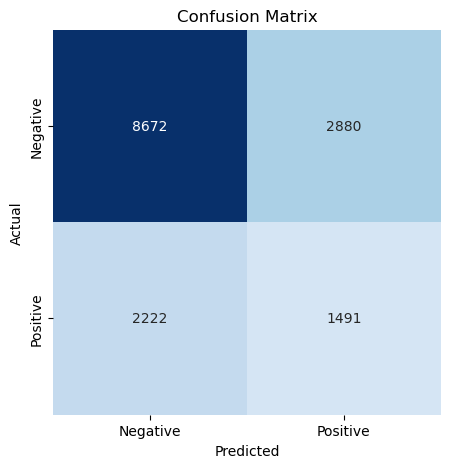

Classification Report:
-------------------------------
               precision    recall  f1-score   support

    Negative       0.80      0.75      0.77     11552
    Positive       0.34      0.40      0.37      3713

    accuracy                           0.67     15265
   macro avg       0.57      0.58      0.57     15265
weighted avg       0.69      0.67      0.67     15265



In [39]:
acc = model.score(X_test, y_test)
y_pred = model.predict(X_test)

print("Test Accuracy: {:.2f}%".format(acc * 100))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
clr = classification_report(y_test, y_pred, labels=[0, 1], target_names=['Negative', 'Positive'])

plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='g', vmin=0, cmap='Blues', cbar=False)
plt.xticks(ticks=[0.5, 1.5], labels=['Negative', 'Positive'])
plt.yticks(ticks=[0.5, 1.5], labels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print("Classification Report:\n-------------------------------\n", clr)